In [23]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

print("PyTorch Version:", torch.__version__)

# Check GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)


All libraries imported successfully!
PyTorch Version: 2.14.1+cu130
Using Device: cuda


In [24]:

# Step 2: Load Dataset

df = pd.read_csv('/content/loan_data.csv')

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

# Display first five records
df.head()


Dataset loaded successfully!
Dataset Shape: (45000, 14)


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000



========== LOAN STATUS DISTRIBUTION ==========
loan_status
0    35000
1    10000
Name: count, dtype: int64


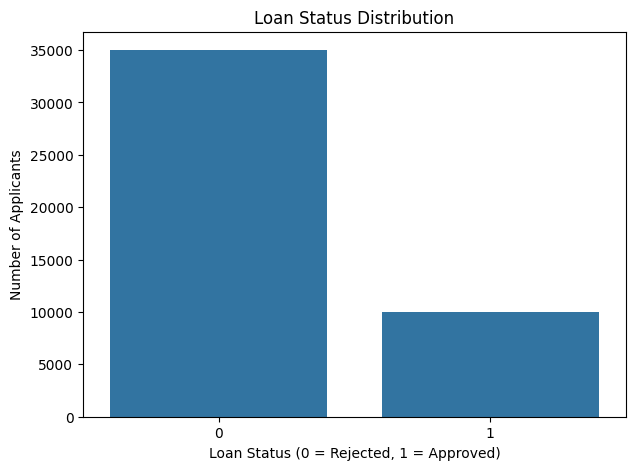

In [25]:

# STEP 3: EXPLORATORY DATA ANALYSIS

# 1. Dataset Information
print("========== DATASET INFORMATION ==========")
df.info()

# 2. Dataset Shape
print("\n========== DATASET SHAPE ==========")
print("Rows and Columns:", df.shape)

# 3. Missing Values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

# 4. Duplicate Records
print("\n========== DUPLICATE RECORDS ==========")
print("Total Duplicates:", df.duplicated().sum())

# 5. Statistical Summary
print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe())

# 6. Loan Status Distribution
print("\n========== LOAN STATUS DISTRIBUTION ==========")
print(df['loan_status'].value_counts())

# 7. Loan Status Visualization
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='loan_status')

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applicants")
plt.show()


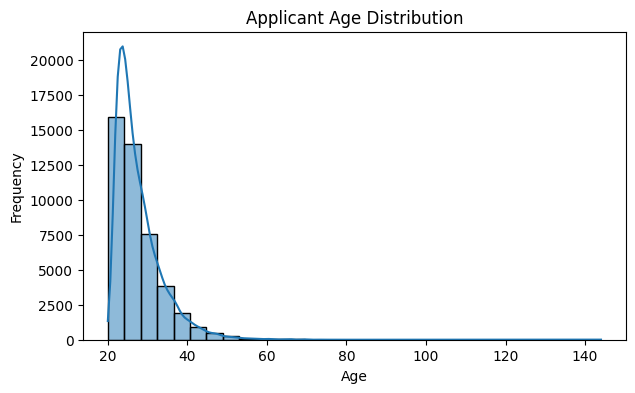

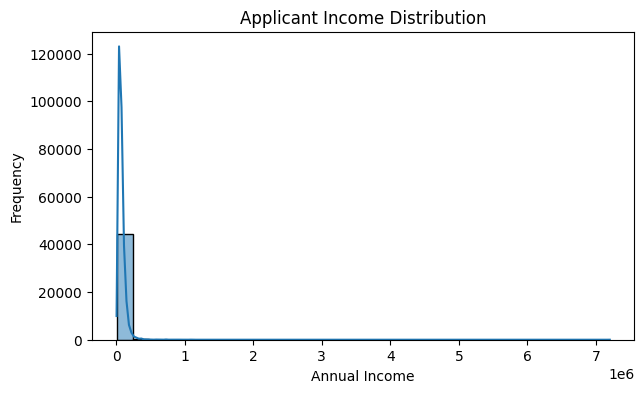

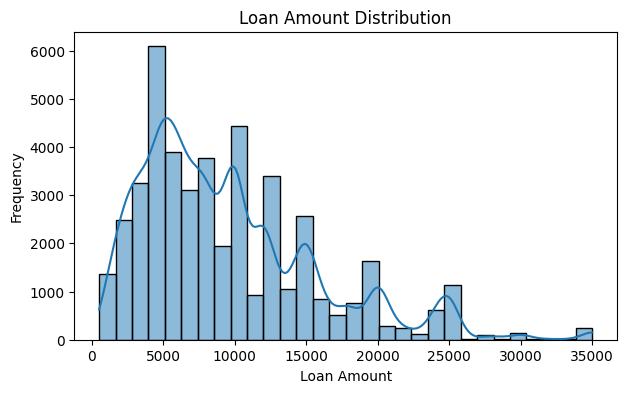

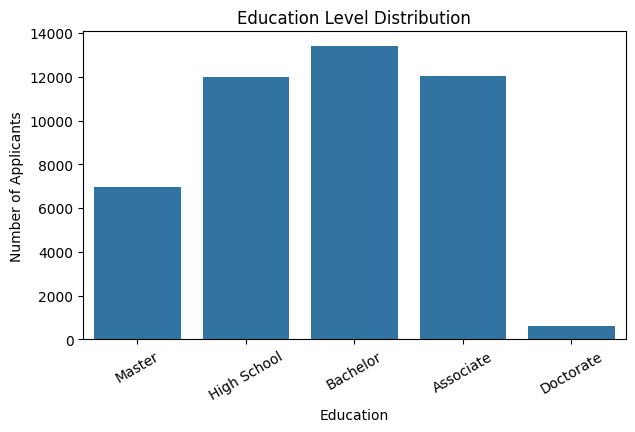

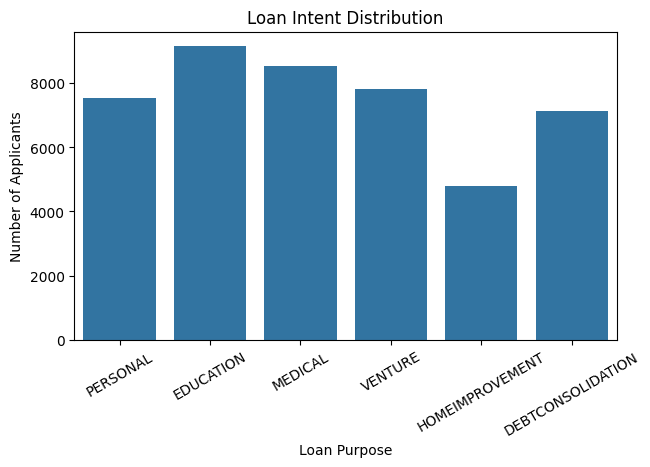

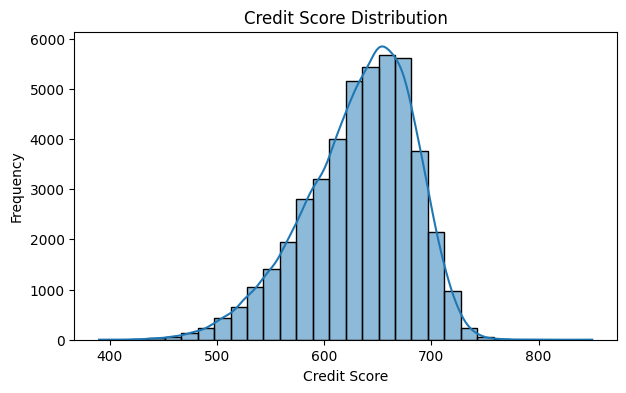

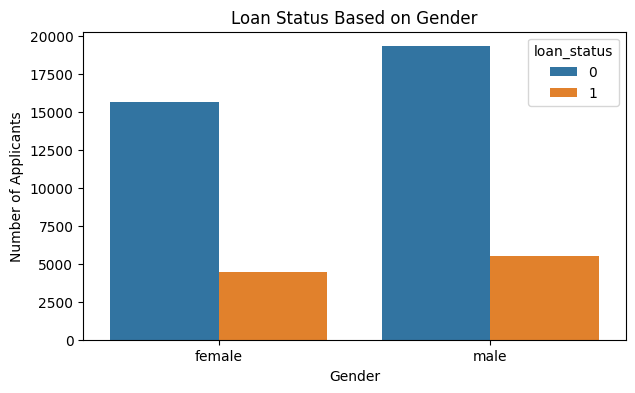

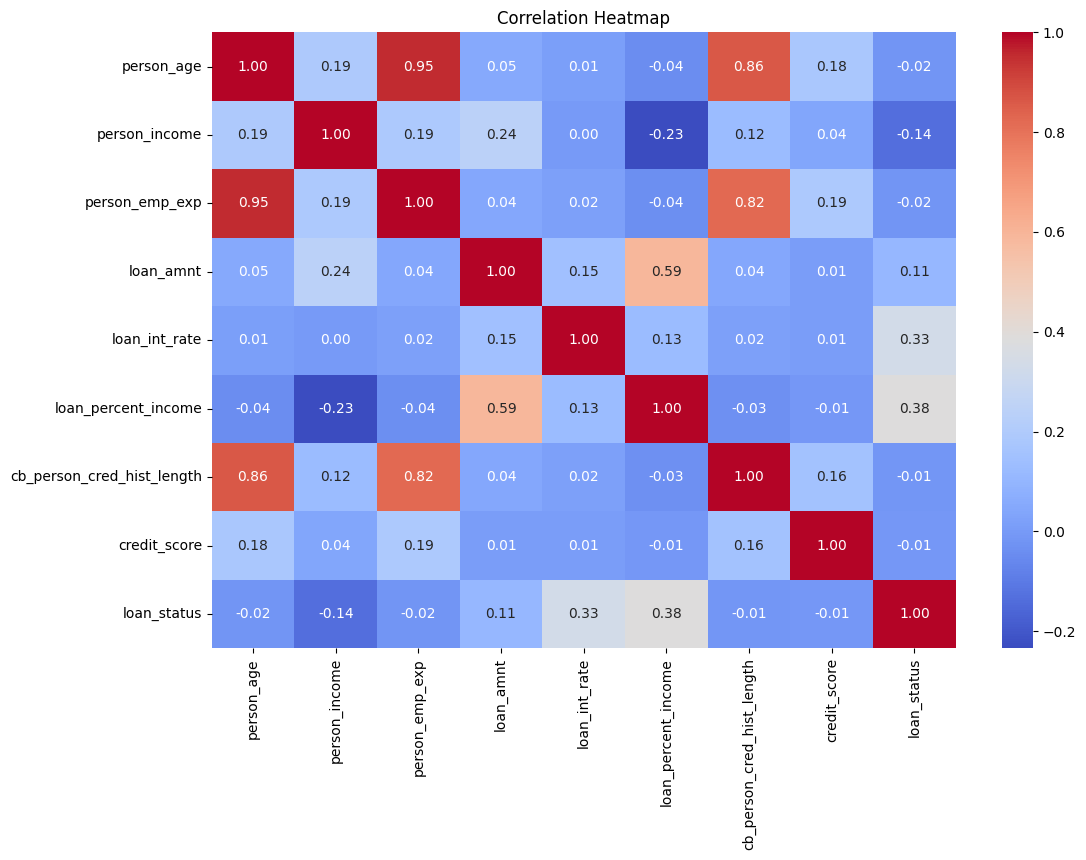

In [26]:

# STEP 4: DATA VISUALIZATION

# 1. Applicant Age Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['person_age'], bins=30, kde=True)
plt.title("Applicant Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


# 2. Applicant Income Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['person_income'], bins=30, kde=True)
plt.title("Applicant Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.show()


# 3. Loan Amount Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['loan_amnt'], bins=30, kde=True)
plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()


# 4. Education Distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='person_education')
plt.title("Education Level Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=30)
plt.show()


# 5. Loan Intent Distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='loan_intent')
plt.title("Loan Intent Distribution")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=30)
plt.show()


# 6. Credit Score Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['credit_score'], bins=30, kde=True)
plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Frequency")
plt.show()


# 7. Loan Status Based on Gender
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='person_gender', hue='loan_status')
plt.title("Loan Status Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()


# 8. Correlation Heatmap
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


In [27]:

# STEP 5: DATA PREPROCESSING

# 1. Separate Input Features and Target
X = df.drop('loan_status', axis=1)
y = df['loan_status']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)


# 2. Identify Numerical and Categorical Columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# 3. Split Dataset into Training, Validation and Testing Sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


# 4. Encode and Normalize Features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)


# 5. Convert Processed Data into Dense Arrays
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

# Convert target variables into NumPy arrays
y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)


# 6. Display Final Dataset Shapes
print("\n========== FINAL DATASET SHAPES ==========")
print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nPreprocessing Completed Successfully!")


Input Features Shape: (45000, 13)
Target Shape: (45000,)

Numerical Features:
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Categorical Features:
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']

========== FINAL DATASET SHAPES ==========
Training Data: (31500, 27)
Validation Data: (6750, 27)
Testing Data: (6750, 27)

Preprocessing Completed Successfully!


In [28]:

# STEP 6: CONVERT DATA INTO PYTORCH TENSORS

# 1. Convert NumPy arrays into PyTorch tensors

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)


# 2. Create TensorDatasets

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


# 3. Create DataLoaders

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# 4. Display tensor information

print("========== PYTORCH TENSOR INFORMATION ==========")

print("Training Input Shape:", X_train_tensor.shape)
print("Training Target Shape:", y_train_tensor.shape)

print("Validation Input Shape:", X_val_tensor.shape)
print("Validation Target Shape:", y_val_tensor.shape)

print("Testing Input Shape:", X_test_tensor.shape)
print("Testing Target Shape:", y_test_tensor.shape)

print("\nNumber of Training Batches:", len(train_loader))
print("Number of Validation Batches:", len(val_loader))
print("Number of Testing Batches:", len(test_loader))

print("\nPyTorch Data Preparation Completed Successfully!")


========== PYTORCH TENSOR INFORMATION ==========
Training Input Shape: torch.Size([31500, 27])
Training Target Shape: torch.Size([31500, 1])
Validation Input Shape: torch.Size([6750, 27])
Validation Target Shape: torch.Size([6750, 1])
Testing Input Shape: torch.Size([6750, 27])
Testing Target Shape: torch.Size([6750, 1])

Number of Training Batches: 493
Number of Validation Batches: 106
Number of Testing Batches: 106

PyTorch Data Preparation Completed Successfully!


**ARTIFICIAL NEURAL NETWORK (ANN)**

In [29]:

# STEP 7: BUILD ARTIFICIAL NEURAL NETWORK

class LoanApprovalANN(nn.Module):

    def __init__(self, input_size):
        super(LoanApprovalANN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1),

        )

    def forward(self, x):
        return self.network(x)


# Get number of input features
input_size = X_train_tensor.shape[1]

# Create ANN model
model = LoanApprovalANN(input_size).to(device)

# Display model architecture
print("ANN Model Architecture:")
print(model)

print("\nTotal Input Features:", input_size)
print("\nModel Created Successfully!")


ANN Model Architecture:
LoanApprovalANN(
  (network): Sequential(
    (0): Linear(in_features=27, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total Input Features: 27

Model Created Successfully!


In [30]:

# STEP 8: TRAINING THE DEEP LEARNING MODEL

# Calculate class weight to handle imbalanced data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
).to(device)

# Define loss function and optimizer
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training settings
epochs = 30
patience = 5
best_val_loss = float('inf')
counter = 0

# Store training history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

print("========== MODEL TRAINING STARTED ==========")

for epoch in range(epochs):

    # ---------------- TRAINING PHASE ----------------
    model.train()
    running_train_loss = 0.0
    train_correct = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Calculate training accuracy
        predictions = (outputs >= 0).float()
        train_correct += (predictions == labels).sum().item()

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    epoch_train_accuracy = train_correct / len(train_loader.dataset)

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    # ---------------- VALIDATION PHASE ----------------
    model.eval()
    running_val_loss = 0.0
    val_correct = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Calculate validation accuracy
            predictions = (outputs >= 0).float()
            val_correct += (predictions == labels).sum().item()

            running_val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    epoch_val_accuracy = val_correct / len(val_loader.dataset)

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    # Display epoch results
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} | "
        f"Validation Loss: {epoch_val_loss:.4f} | "
        f"Training Accuracy: {epoch_train_accuracy:.4f} | "
        f"Validation Accuracy: {epoch_val_accuracy:.4f}"
    )

    # Save the best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        counter = 0
    else:
        counter += 1

    # Early stopping
    if counter >= patience:
        print("Early stopping activated!")
        break

# Restore the best model
model.load_state_dict(best_model_state)

print("\n========== TRAINING COMPLETED ==========")
print("Best Validation Loss:", round(best_val_loss, 4))
print("Best Training Accuracy:", round(max(train_accuracies), 4))
print("Best Validation Accuracy:", round(max(val_accuracies), 4))



========== MODEL TRAINING STARTED ==========
Epoch [1/30] Training Loss: 0.4726 | Validation Loss: 0.3718 | Training Accuracy: 0.8432 | Validation Accuracy: 0.8649
Epoch [2/30] Training Loss: 0.3778 | Validation Loss: 0.3625 | Training Accuracy: 0.8715 | Validation Accuracy: 0.8849
Epoch [3/30] Training Loss: 0.3637 | Validation Loss: 0.3629 | Training Accuracy: 0.8796 | Validation Accuracy: 0.8627
Epoch [4/30] Training Loss: 0.3549 | Validation Loss: 0.3601 | Training Accuracy: 0.8804 | Validation Accuracy: 0.8966
Epoch [5/30] Training Loss: 0.3496 | Validation Loss: 0.3518 | Training Accuracy: 0.8823 | Validation Accuracy: 0.8699
Epoch [6/30] Training Loss: 0.3421 | Validation Loss: 0.3481 | Training Accuracy: 0.8848 | Validation Accuracy: 0.8738
Epoch [7/30] Training Loss: 0.3412 | Validation Loss: 0.3501 | Training Accuracy: 0.8832 | Validation Accuracy: 0.8923
Epoch [8/30] Training Loss: 0.3371 | Validation Loss: 0.3483 | Training Accuracy: 0.8874 | Validation Accuracy: 0.8981
Epo

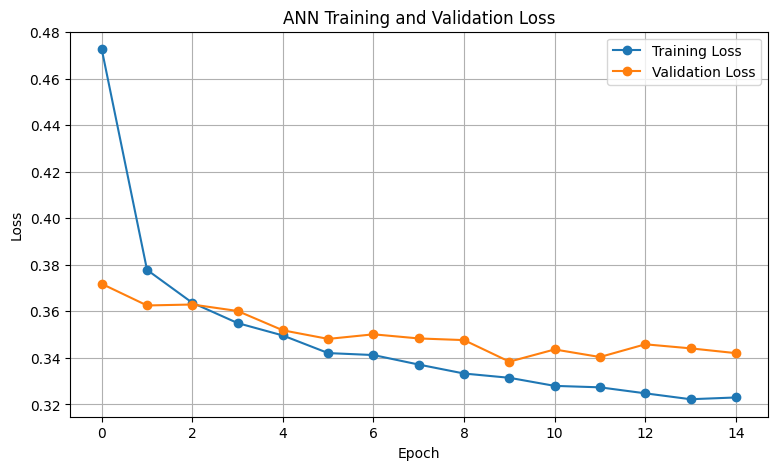

Training Epochs Completed: 15
Final Training Loss: 0.323
Final Validation Loss: 0.342


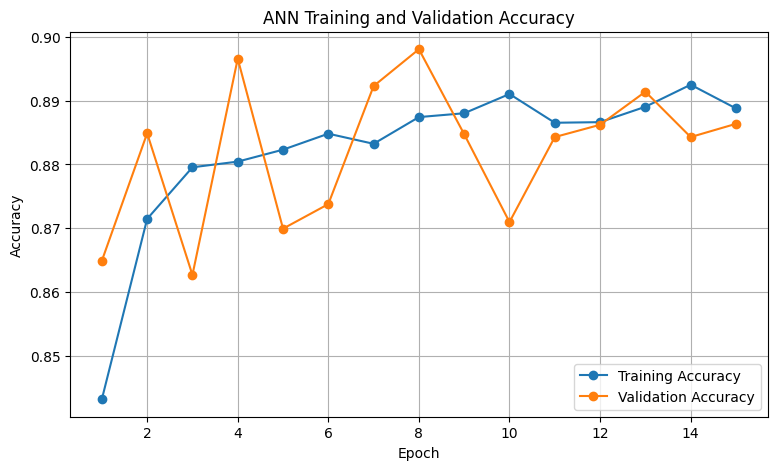

In [31]:

# STEP 9: VISUALIZE TRAINING PERFORMANCE

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label='Training Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='o')

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

print("Training Epochs Completed:", len(train_losses))
print("Final Training Loss:", round(train_losses[-1], 4))
print("Final Validation Loss:", round(val_losses[-1], 4))

# ANN TRAINING AND VALIDATION ACCURACY GRAPH

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(train_accuracies) + 1),
    train_accuracies,
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    label='Validation Accuracy',
    marker='o'
)

plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()



In [32]:

# STEP 10: MODEL EVALUATION

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():
    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        # Get model predictions
        outputs = model(inputs)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities into class labels
        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(predictions.cpu().numpy().flatten())
        all_actuals.extend(labels.numpy().flatten())

# Calculate evaluation metrics
accuracy = accuracy_score(all_actuals, all_predictions)
precision = precision_score(all_actuals, all_predictions, zero_division=0)
recall = recall_score(all_actuals, all_predictions, zero_division=0)
f1 = f1_score(all_actuals, all_predictions, zero_division=0)

print("========== MODEL PERFORMANCE ==========")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(all_actuals, all_predictions, zero_division=0))


========== MODEL PERFORMANCE ==========
Accuracy  : 86.96%
Precision : 64.43%
Recall    : 92.27%
F1-Score  : 75.88%

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         0.0       0.97      0.85      0.91      5250
         1.0       0.64      0.92      0.76      1500

    accuracy                           0.87      6750
   macro avg       0.81      0.89      0.83      6750
weighted avg       0.90      0.87      0.88      6750



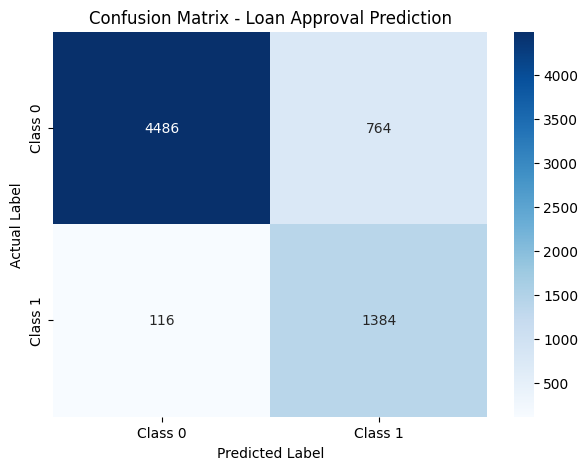

Confusion Matrix:
[[4486  764]
 [ 116 1384]]


In [33]:

# STEP 11: CONFUSION MATRIX

cm = confusion_matrix(all_actuals, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1']
)

plt.title('Confusion Matrix - Loan Approval Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

print("Confusion Matrix:")
print(cm)


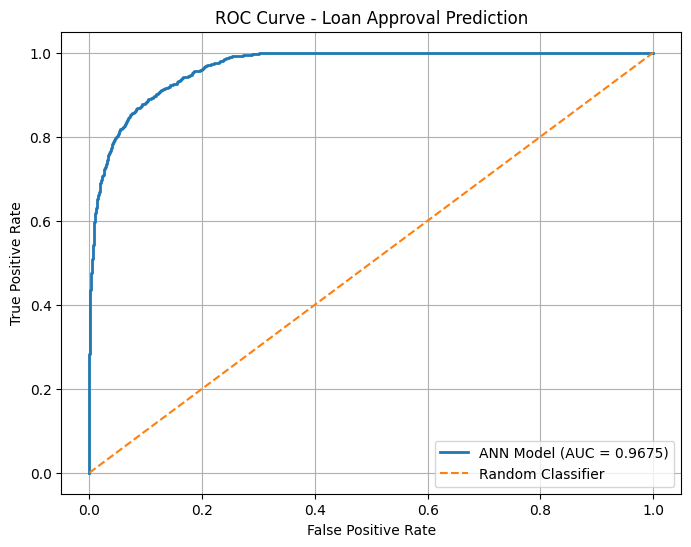

ROC AUC Score: 0.9675


In [34]:

# STEP 12: ROC CURVE AND AUC SCORE

from sklearn.metrics import roc_curve, roc_auc_score

# Store prediction probabilities
y_probabilities = []

model.eval()

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        probabilities = torch.sigmoid(outputs)

        y_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    all_actuals,
    y_probabilities
)

# Calculate AUC
auc_score = roc_auc_score(
    all_actuals,
    y_probabilities
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'ANN Model (AUC = {auc_score:.4f})',
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve - Loan Approval Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

print("ROC AUC Score:", round(auc_score, 4))


**GRU MODEL**

In [35]:

# STEP 1: BUILD GRU MODEL

class LoanApprovalGRU(nn.Module):

    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super(LoanApprovalGRU, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        output, hidden = self.gru(x)

        # Get the final sequence output
        output = output[:, -1, :]

        output = self.fc1(output)
        output = self.relu(output)
        output = self.dropout(output)
        output = self.fc2(output)

        return output


gru_model = LoanApprovalGRU().to(device)

print("GRU Model Architecture:")
print(gru_model)


GRU Model Architecture:
LoanApprovalGRU(
  (gru): GRU(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [36]:

# STEP 2: TRAIN GRU MODEL

# Calculate class weight to handle imbalanced data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

gru_pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
).to(device)

# Define loss function and optimizer
criterion_gru = nn.BCEWithLogitsLoss(pos_weight=gru_pos_weight)
optimizer_gru = optim.Adam(gru_model.parameters(), lr=0.001)

# Training settings
epochs = 30
patience = 5
best_val_loss = float('inf')
counter = 0

# Store training history
gru_train_losses = []
gru_val_losses = []
gru_train_accuracies = []
gru_val_accuracies = []

print("========== GRU TRAINING STARTED ==========")

for epoch in range(epochs):

    # ---------------- TRAINING PHASE ----------------
    gru_model.train()
    train_loss = 0.0
    train_correct = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device).unsqueeze(-1)
        labels = labels.to(device)

        optimizer_gru.zero_grad()

        outputs = gru_model(inputs)
        loss = criterion_gru(outputs, labels)

        # Calculate training accuracy
        predictions = (outputs >= 0).float()
        train_correct += (predictions == labels).sum().item()

        loss.backward()
        optimizer_gru.step()

        train_loss += loss.item() * inputs.size(0)

    epoch_train_loss = train_loss / len(train_loader.dataset)
    epoch_train_accuracy = train_correct / len(train_loader.dataset)

    gru_train_losses.append(epoch_train_loss)
    gru_train_accuracies.append(epoch_train_accuracy)

    # ---------------- VALIDATION PHASE ----------------
    gru_model.eval()
    val_loss = 0.0
    val_correct = 0

    with torch.no_grad():
        for inputs, labels in val_loader:

            inputs = inputs.to(device).unsqueeze(-1)
            labels = labels.to(device)

            outputs = gru_model(inputs)
            loss = criterion_gru(outputs, labels)

            # Calculate validation accuracy
            predictions = (outputs >= 0).float()
            val_correct += (predictions == labels).sum().item()

            val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_accuracy = val_correct / len(val_loader.dataset)

    gru_val_losses.append(epoch_val_loss)
    gru_val_accuracies.append(epoch_val_accuracy)

    # Display epoch results
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} | "
        f"Validation Loss: {epoch_val_loss:.4f} | "
        f"Training Accuracy: {epoch_train_accuracy:.4f} | "
        f"Validation Accuracy: {epoch_val_accuracy:.4f}"
    )

    # Save the best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_gru_state = {
            key: value.detach().cpu().clone()
            for key, value in gru_model.state_dict().items()
        }
        counter = 0
    else:
        counter += 1

    # Early stopping
    if counter >= patience:
        print("Early stopping activated!")
        break

# Restore the best model
gru_model.load_state_dict(best_gru_state)

print("\n========== GRU TRAINING COMPLETED ==========")
print("Best Validation Loss:", round(best_val_loss, 4))
print("Best Training Accuracy:", round(max(gru_train_accuracies), 4))
print("Best Validation Accuracy:", round(max(gru_val_accuracies), 4))


========== GRU TRAINING STARTED ==========
Epoch [1/30] Training Loss: 0.6672 | Validation Loss: 0.5842 | Training Accuracy: 0.7160 | Validation Accuracy: 0.7344
Epoch [2/30] Training Loss: 0.5863 | Validation Loss: 0.5622 | Training Accuracy: 0.7308 | Validation Accuracy: 0.7344
Epoch [3/30] Training Loss: 0.5253 | Validation Loss: 0.4710 | Training Accuracy: 0.7897 | Validation Accuracy: 0.8307
Epoch [4/30] Training Loss: 0.4553 | Validation Loss: 0.4351 | Training Accuracy: 0.8332 | Validation Accuracy: 0.8230
Epoch [5/30] Training Loss: 0.4354 | Validation Loss: 0.4216 | Training Accuracy: 0.8443 | Validation Accuracy: 0.8286
Epoch [6/30] Training Loss: 0.4243 | Validation Loss: 0.4055 | Training Accuracy: 0.8515 | Validation Accuracy: 0.8436
Epoch [7/30] Training Loss: 0.4160 | Validation Loss: 0.3923 | Training Accuracy: 0.8530 | Validation Accuracy: 0.8524
Epoch [8/30] Training Loss: 0.4073 | Validation Loss: 0.3974 | Training Accuracy: 0.8568 | Validation Accuracy: 0.8299
Epoch

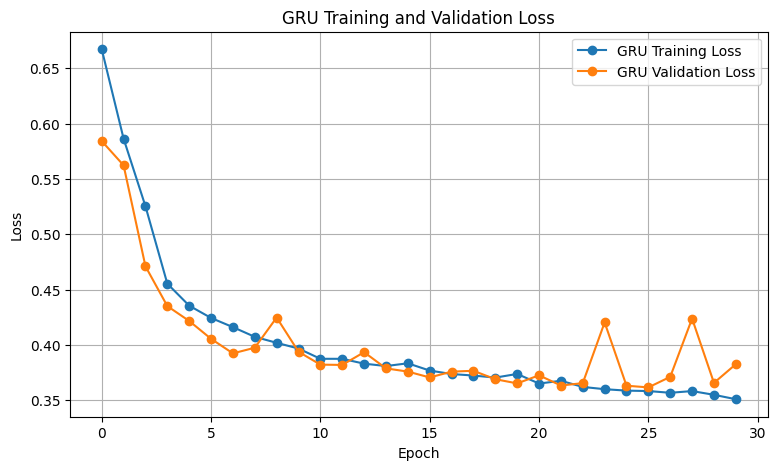

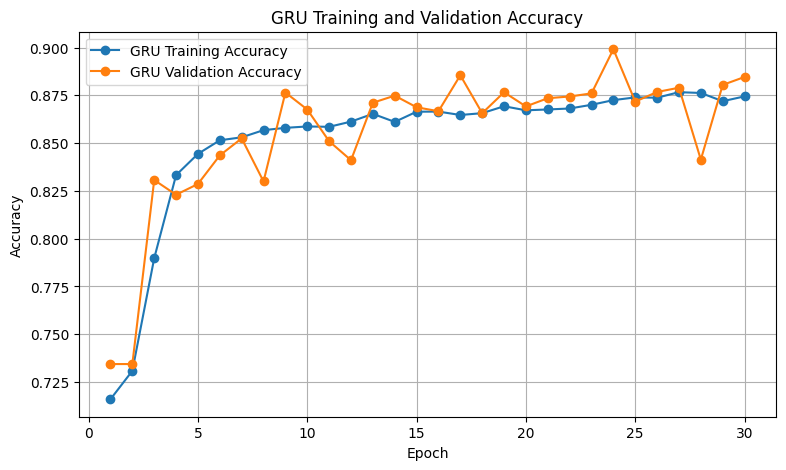

In [37]:

# STEP 3: GRU TRAINING GRAPH

plt.figure(figsize=(9, 5))

plt.plot(gru_train_losses, label='GRU Training Loss', marker='o')
plt.plot(gru_val_losses, label='GRU Validation Loss', marker='o')

plt.title('GRU Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()


# GRU TRAINING AND VALIDATION ACCURACY GRAPH

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(gru_train_accuracies) + 1),
    gru_train_accuracies,
    label='GRU Training Accuracy',
    marker='o'
)

plt.plot(
    range(1, len(gru_val_accuracies) + 1),
    gru_val_accuracies,
    label='GRU Validation Accuracy',
    marker='o'
)

plt.title('GRU Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()



In [38]:

# STEP 4: GRU MODEL EVALUATION

gru_model.eval()

gru_predictions = []
gru_actuals = []
gru_probabilities = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device).unsqueeze(-1)

        outputs = gru_model(inputs)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).float()

        gru_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

        gru_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

        gru_actuals.extend(
            labels.numpy().flatten()
        )

# Calculate metrics
gru_accuracy = accuracy_score(gru_actuals, gru_predictions)
gru_precision = precision_score(gru_actuals, gru_predictions, zero_division=0)
gru_recall = recall_score(gru_actuals, gru_predictions, zero_division=0)
gru_f1 = f1_score(gru_actuals, gru_predictions, zero_division=0)

print("========== GRU PERFORMANCE ==========")

print(f"Accuracy  : {gru_accuracy * 100:.2f}%")
print(f"Precision : {gru_precision * 100:.2f}%")
print(f"Recall    : {gru_recall * 100:.2f}%")
print(f"F1-Score  : {gru_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    gru_actuals,
    gru_predictions,
    zero_division=0
))


========== GRU PERFORMANCE ==========
Accuracy  : 87.47%
Precision : 66.00%
Recall    : 89.93%
F1-Score  : 76.13%

Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.87      0.92      5250
         1.0       0.66      0.90      0.76      1500

    accuracy                           0.87      6750
   macro avg       0.81      0.88      0.84      6750
weighted avg       0.90      0.87      0.88      6750



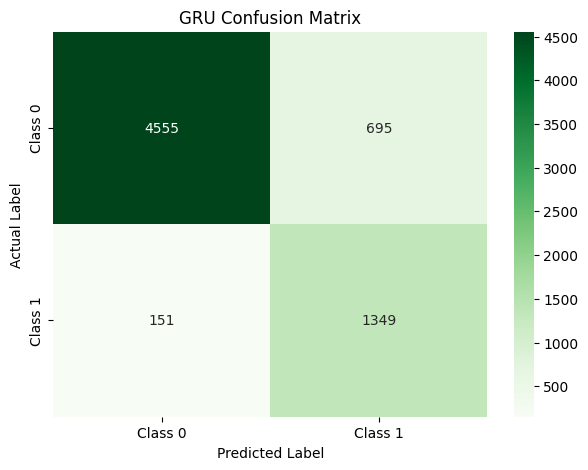

[[4555  695]
 [ 151 1349]]


In [39]:

# STEP 5: GRU CONFUSION MATRIX

gru_cm = confusion_matrix(gru_actuals, gru_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    gru_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1']
)

plt.title('GRU Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

print(gru_cm)


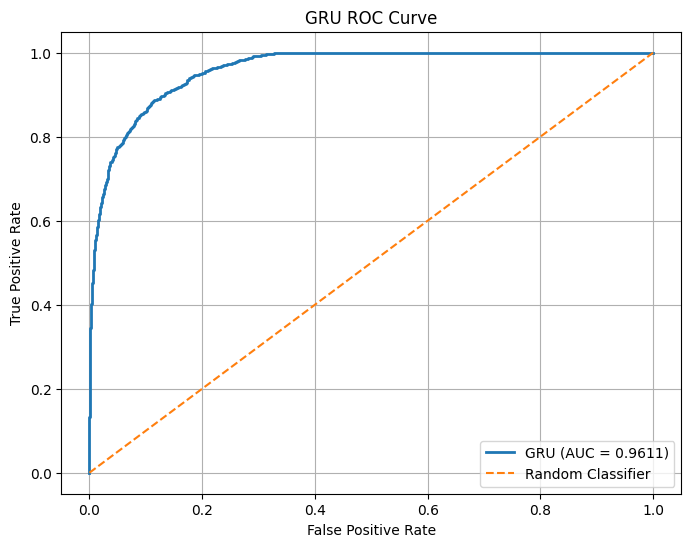

GRU ROC-AUC Score: 0.9611


In [40]:

# STEP 6: GRU ROC CURVE

gru_fpr, gru_tpr, gru_thresholds = roc_curve(
    gru_actuals,
    gru_probabilities
)

gru_auc = roc_auc_score(
    gru_actuals,
    gru_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    gru_fpr,
    gru_tpr,
    label=f'GRU (AUC = {gru_auc:.4f})',
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('GRU ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)

plt.show()

print("GRU ROC-AUC Score:", round(gru_auc, 4))


**COMPARISION OF ANN AND GRU MODELS**

========== ANN VS GRU COMPARISON ==========


,Metric,ANN,GRU
0,Accuracy,0.8696,0.8747
1,Precision,0.6443,0.6600
2,Recall,0.9227,0.8993
3,F1-Score,0.7588,0.7613
4,ROC-AUC,0.9675,0.9611


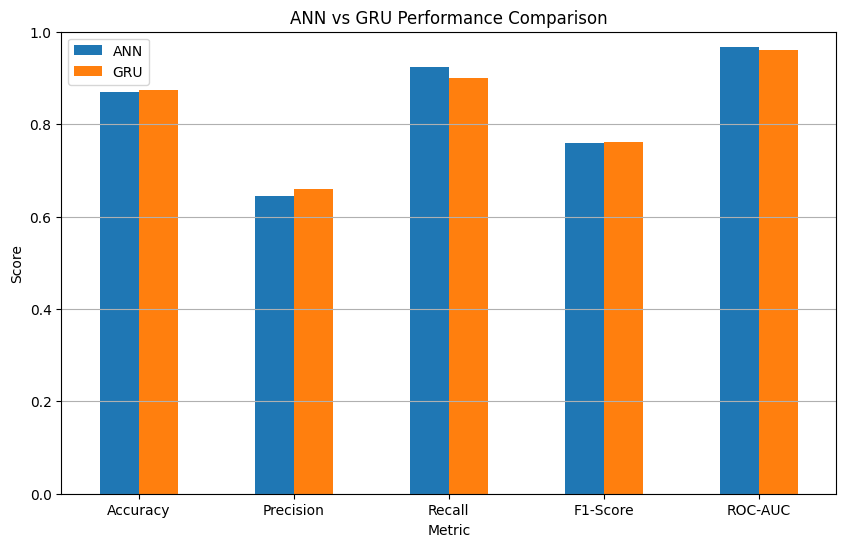

In [41]:

# STEP 7: ANN VS GRU COMPARISON

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],

    'ANN': [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ],

    'GRU': [
        gru_accuracy,
        gru_precision,
        gru_recall,
        gru_f1,
        gru_auc
    ]
})

print("========== ANN VS GRU COMPARISON ==========")

display(comparison.round(4))

comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('ANN vs GRU Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.legend()
plt.show()
